# Random Forests
**Name:** GUNTI RAHUL|  **Roll No:** CH.SC.U4CSE24211
**Course:** Machine Learning (23CSE301)  |  **Lab Activity Book:** Chapter 12.6

## Exercise 1 - Which fruit is taken most often?
In the figure, the three trees predict **Tree-1 = Apple (A), Tree-2 = Apple (A), Tree-n = Banana (B)**. A random forest outputs the **majority vote**, so the final class is **Apple**.

In [1]:
from collections import Counter
votes = {"Tree-1": "Apple", "Tree-2": "Apple", "Tree-n": "Banana"}
tally = Counter(votes.values()); print(tally)
print("Final class:", tally.most_common(1)[0][0])

Counter({'Apple': 2, 'Banana': 1})
Final class: Apple


To show the same mechanism with a real ensemble, build a fruit basket (weight, diameter, colour score, sweetness) and train a forest of trees, then inspect each tree's vote.

        weight  diameter  colour  sweetness
fruit                                      
Apple   153.77      7.52    0.28       5.86
Banana  120.87      3.46    0.80       7.13
Orange  179.70      7.94    0.53       4.93


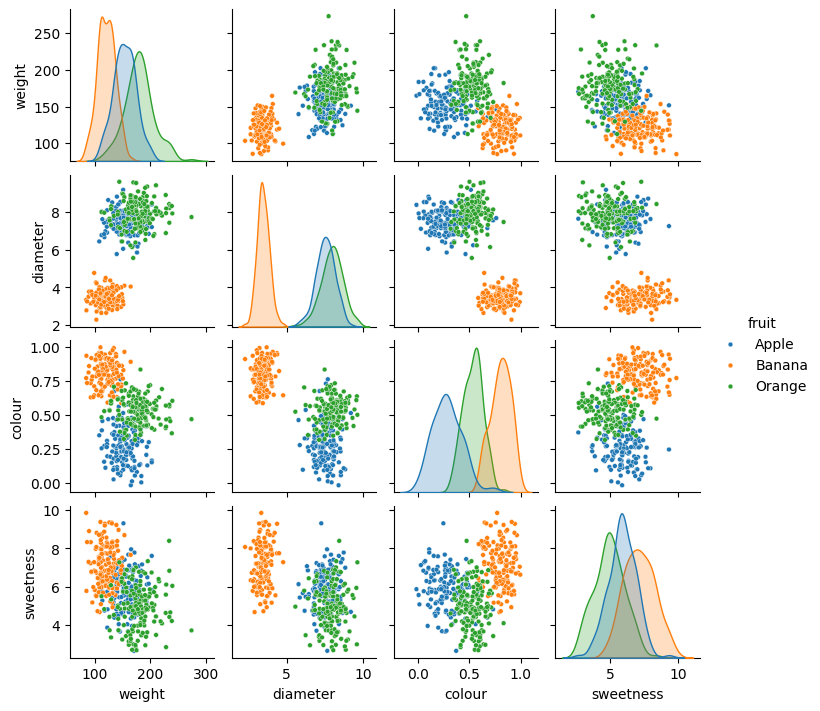

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

r = np.random.default_rng(262)
def fruit(name, n, w, d, c, s): return pd.DataFrame({"weight": r.normal(*w, n), "diameter": r.normal(*d, n), "colour": r.normal(*c, n), "sweetness": r.normal(*s, n), "fruit": name})
basket = pd.concat([fruit("Apple", 150, (150, 20), (7.5, .6), (.3, .15), (6, 1)),
                    fruit("Banana", 150, (120, 15), (3.5, .4), (.8, .1), (7, 1)),
                    fruit("Orange", 150, (180, 25), (8, .7), (.55, .1), (5, 1))], ignore_index=True)
print(basket.groupby("fruit").mean().round(2))
sns.pairplot(basket, hue="fruit", height=1.8, plot_kws=dict(s=12)); plt.show()

Single tree accuracy : 0.85
Random forest acc.   : 0.876 | OOB score: 0.926
              precision    recall  f1-score   support

       Apple       0.79      0.87      0.82        38
      Banana       1.00      1.00      1.00        38
      Orange       0.85      0.76      0.80        37

    accuracy                           0.88       113
   macro avg       0.88      0.88      0.88       113
weighted avg       0.88      0.88      0.88       113



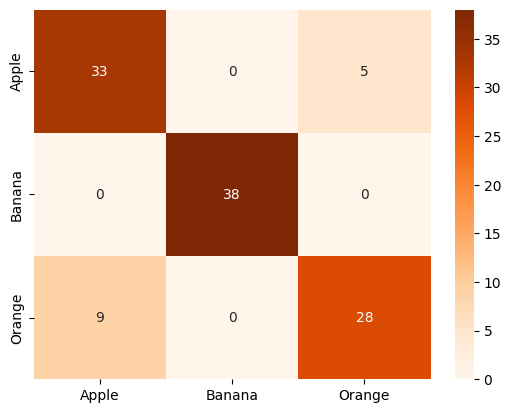

In [3]:
X, y = basket.drop(columns="fruit"), basket["fruit"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, random_state=262, stratify=y)
single = DecisionTreeClassifier(random_state=262).fit(Xtr, ytr)
rf = RandomForestClassifier(n_estimators=100, random_state=262, oob_score=True).fit(Xtr, ytr)
print("Single tree accuracy :", round(single.score(Xte, yte), 3))
print("Random forest acc.   :", round(rf.score(Xte, yte), 3), "| OOB score:", round(rf.oob_score_, 3))
pred = rf.predict(Xte); print(classification_report(yte, pred))
sns.heatmap(confusion_matrix(yte, pred, labels=rf.classes_), annot=True, fmt="d", xticklabels=rf.classes_, yticklabels=rf.classes_, cmap="Oranges"); plt.show()

Per-tree votes: Counter({'Banana': 100})
Forest majority vote: Banana | forest.predict: Banana | true: Banana


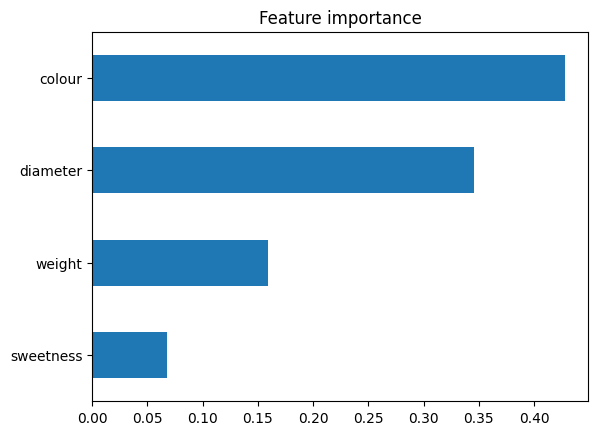

In [4]:
sample = Xte.iloc[[0]]
tree_votes = [rf.classes_[int(t.predict(sample.values)[0])] for t in rf.estimators_]
print("Per-tree votes:", Counter(tree_votes)); print("Forest majority vote:", Counter(tree_votes).most_common(1)[0][0], "| forest.predict:", rf.predict(sample)[0], "| true:", yte.iloc[0])
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(); imp.plot.barh(); plt.title("Feature importance"); plt.show()

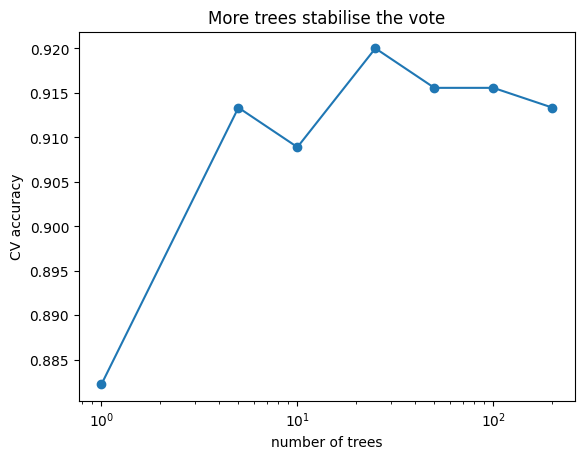

In [5]:
sizes = [1, 5, 10, 25, 50, 100, 200]
acc = [cross_val_score(RandomForestClassifier(n_estimators=n, random_state=262), X, y, cv=5).mean() for n in sizes]
plt.plot(sizes, acc, "o-"); plt.xscale("log"); plt.xlabel("number of trees"); plt.ylabel("CV accuracy"); plt.title("More trees stabilise the vote"); plt.show()

### Conclusion
The forest's answer for the basket in the book is **Apple** (2 votes to 1). On real data, averaging many de-correlated trees beats a single deep tree, the out-of-bag score gives a free validation estimate, and feature importances show which measurements drive the decision.